# MarketPulse AI — Can News Sentiment Really Predict the Stock Market?
**Veritas AI International High School Hackathon 2026 · Track: AI + Finance · Project 4.2.4 (News Headlines and the Stock Market)**
**Team:** _[Atharva Saxena]_

> **This project is a prototype and is not financial advice.**

**Research question.** Does the sentiment of each day's top-25 world-news headlines tell us anything about whether the Dow Jones Industrial Average (DJIA) went up or down — and **do financial headlines work better than general ones** (our original contribution)?

**How to read this notebook:** every number and chart below is computed when you run the cells. Nothing is typed in by hand. The test period (2015-2016) is touched only for final evaluation; all model choices use a validation year (2014) taken from inside the training period.

| Part | What happens |
|---|---|
| 0 | Setup, data download |
| 1 | Data cleaning, exploration, chronological split |
| 2 | VADER sentiment → daily features |
| 3 | Baselines + Logistic Regression + Random Forest (Phase 1 / MVP) |
| 4 | **Original research: financial vs. general news** (Phase 2) |
| 5 | Evaluation charts, error analysis, failure examples |
| 6 | Save the model for the Gradio demo (`app.py`) |

In [3]:
!git clone https://github.com/atharvasaxena0405-star/MarketPulse-AI.git
%cd MarketPulse-AI
!pip install -r requirements.txt

Cloning into 'MarketPulse-AI'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 30 (delta 4), reused 22 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 3.49 MiB | 16.76 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/MarketPulse-AI/MarketPulse-AI


## 0 · Setup

In [4]:
# Google Colab: run this cell once. Locally: `pip install -r requirements.txt`.
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk", "scikit-learn", "pandas", "numpy", "matplotlib", "scipy", "joblib"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'nltk', 'scikit-learn', 'pandas', 'numpy', 'matplotlib', 'scipy', 'joblib'], returncode=0)

In [5]:
%%writefile marketpulse.py
"""MarketPulse AI - shared helpers (data cleaning, VADER sentiment, financial-news filter, features).

Used by both the notebook (MarketPulse_AI.ipynb) and the Gradio demo (app.py)
so the demo uses exactly the same feature code as the experiments.
"""
import re
import numpy as np
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

HEADLINE_COLS = [f"Top{i}" for i in range(1, 26)]
TRAIN_END = "2014-12-31"   # training: 2008-08-08 .. 2014-12-31
TEST_START = "2015-01-01"  # test:     2015-01-01 .. 2016-07-01
VAL_START = "2014-01-01"   # validation (inside training): 2014 only

# --------------------------------------------------------------------------- #
# 1. Cleaning
# --------------------------------------------------------------------------- #
def clean_headline(text):
    """The CSV stores headlines as Python byte-string reprs, e.g.  b'Some headline'  or  b"It's ...".
    Strip that prefix and the wrapping quotes, then tidy whitespace."""
    if not isinstance(text, str):
        return ""
    t = text.strip()
    if len(t) >= 3 and t[0] == "b" and t[1] in "'\"" and t[-1] == t[1]:
        t = t[2:-1]
    t = t.replace("\\'", "'").replace('\\"', '"').replace("\\n", " ")
    return re.sub(r"\s+", " ", t).strip()


def load_news(path):
    """Load CSV, parse dates, sort chronologically, clean all headline cells.
    Missing headlines (a handful of NaN cells) become '' and are skipped later."""
    df = pd.read_csv(path)
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)   # chronological, NEVER shuffled
    for c in HEADLINE_COLS:
        df[c] = df[c].map(clean_headline)
    return df


def headlines_of(row):
    return [row[c] for c in HEADLINE_COLS if row[c]]

# --------------------------------------------------------------------------- #
# 2. VADER sentiment
# --------------------------------------------------------------------------- #
_sia = None
def get_vader():
    global _sia
    if _sia is None:
        try:
            nltk.data.find("sentiment/vader_lexicon.zip")
        except LookupError:
            nltk.download("vader_lexicon", quiet=True)
        _sia = SentimentIntensityAnalyzer()
    return _sia


def score_headlines(headlines):
    """Return DataFrame with VADER neg/neu/pos/compound for each headline."""
    sia = get_vader()
    rows = [sia.polarity_scores(h) for h in headlines]
    return pd.DataFrame(rows, columns=["neg", "neu", "pos", "compound"])

# --------------------------------------------------------------------------- #
# 3. Financial-news keyword classifier (our original contribution)
# --------------------------------------------------------------------------- #
# Word-boundary regexes. Deliberately transparent so students can explain every rule.
FIN_CATEGORIES = {
    "fed_rates": r"\b(federal reserve|the fed|fed rate|interest rates?|rate (cut|hike|rise)s?|central bank|ecb|bank of (england|japan|china)|bernanke|yellen|draghi|monetary policy|quantitative easing|bond yields?|treasur(y|ies))\b",
    "inflation_jobs": r"\b(inflation|deflation|unemployment|jobless|jobs report|payrolls?|wages?|cost of living|consumer prices?|cpi)\b",
    "growth": r"\b(gdp|recession|economic growth|economy|economic|slowdown|downturn|stimulus|austerity|recovery|depression)\b",
    "banks_markets": r"\b(banks?|banking|stock markets?|stocks?|shares|wall street|dow jones|nasdaq|nikkei|ftse|s&p|hedge funds?|investors?|bailout|bankrupt(cy)?|debt|default|credit|lehman|financial|finance|currency|euro|dollar|yuan|sterling|forex|bitcoin|imf|world bank|market|markets)\b",
    "earnings_corp": r"\b(earnings|profits?|revenues?|quarterly|ipo|merger|takeover|acquisition|acquires?|shareholders?|ceo|corporate|corporation|company|companies|bonus(es)?|oil prices?|crude|opec|gold prices?)\b",
    "trade_policy": r"\b(trade|tariffs?|sanctions?|exports?|imports?|embargo|subsid(y|ies)|taxes|tax|taxation|budget|deficit|fiscal|wto|trade deal|currency war)\b",
}
_FIN_RE = {k: re.compile(v, re.I) for k, v in FIN_CATEGORIES.items()}


def fin_categories(headline):
    """Which financial categories (if any) a headline matches."""
    return [k for k, rx in _FIN_RE.items() if rx.search(headline)]


def is_financial(headline):
    return any(rx.search(headline) for rx in _FIN_RE.values())

# --------------------------------------------------------------------------- #
# 4. Daily feature engineering
# --------------------------------------------------------------------------- #
POS_T, NEG_T = 0.05, -0.05   # standard VADER thresholds on the compound score
AGG_NAMES = ["mean", "median", "std", "min", "max", "pct_neg", "pct_pos", "mean_pos", "mean_neg", "mean_neu"]


def aggregate(scores):
    """Turn per-headline VADER scores into one row of daily features (dict, no prefix).
    Empty input -> neutral zeros (documented imputation)."""
    if scores is None or len(scores) == 0:
        return {k: 0.0 for k in AGG_NAMES}
    c = scores["compound"]
    return {
        "mean": c.mean(), "median": c.median(),
        "std": c.std(ddof=0),
        "min": c.min(), "max": c.max(),
        "pct_neg": (c <= NEG_T).mean(), "pct_pos": (c >= POS_T).mean(),
        "mean_pos": scores["pos"].mean(), "mean_neg": scores["neg"].mean(), "mean_neu": scores["neu"].mean(),
    }


def daily_features_from_headlines(headlines):
    """Features for ONE day's list of headlines (used by the demo and by the dataset builder)."""
    sc = score_headlines(headlines) if len(headlines) else pd.DataFrame(columns=["neg", "neu", "pos", "compound"])
    fin_mask = np.array([is_financial(h) for h in headlines], dtype=bool) if len(headlines) else np.array([], dtype=bool)
    out = {f"all_{k}": v for k, v in aggregate(sc).items()}
    out.update({f"fin_{k}": v for k, v in aggregate(sc[fin_mask] if len(sc) else sc).items()})
    out["fin_count"] = float(fin_mask.sum())
    out["fin_frac"] = float(fin_mask.mean()) if len(fin_mask) else 0.0
    out["n_headlines"] = float(len(headlines))
    return out


def build_feature_table(df):
    """One row per trading day; keeps Date and Label. Pure per-day function => no cross-day leakage."""
    feats = [daily_features_from_headlines(headlines_of(r)) for _, r in df.iterrows()]
    out = pd.concat([df[["Date", "Label"]].reset_index(drop=True), pd.DataFrame(feats)], axis=1)
    return out


def add_market_history(ft):
    """Previous-day direction features. Label(D-1) is known before D's open, so these are legal inputs."""
    ft = ft.copy()
    ft["prev_dir"] = ft["Label"].shift(1)
    ft["prev_up_rate5"] = ft["Label"].shift(1).rolling(5, min_periods=1).mean()
    return ft


def lag_news(ft, cols):
    """Strict pre-market variant: use YESTERDAY's headline features to predict TODAY's label."""
    ft = ft.copy()
    ft[cols] = ft[cols].shift(1)
    return ft


def feature_columns(group):
    """group in {'all','fin','both'}"""
    all_cols = [f"all_{k}" for k in AGG_NAMES]
    fin_cols = [f"fin_{k}" for k in AGG_NAMES] + ["fin_count", "fin_frac"]
    return {"all": all_cols, "fin": fin_cols, "both": all_cols + fin_cols}[group]

Overwriting marketpulse.py


The cell above writes `marketpulse.py` — our shared helper module (cleaning, VADER scoring, the financial-news keyword filter and feature builder). The Gradio demo imports the **same** file, so the demo and the experiments can never disagree about how features are computed.

In [6]:
import os, json, warnings, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display, Markdown
import marketpulse as mp
warnings.filterwarnings("ignore")

SEED = 0
np.random.seed(SEED)
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)
RESULTS = {}   # everything we report is collected here and saved to results.json at the end

# ---- consistent chart style (blue = ML / all news, orange = financial news, grey = baselines) ----
BLUE, ORANGE, GREY, INK, MUTED, SURF = "#2a78d6", "#eb6834", "#9a9a95", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe6",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "savefig.facecolor": SURF})
def savefig(name):
    plt.savefig(f"figures/{name}.png"); plt.show()

DATA_PATH = "data/Combined_News_DJIA.csv"
URLS = ["https://huggingface.co/datasets/abhimlv/ESMPT-Dataset/resolve/main/raw/Combined_News_DJIA.csv"]
if not os.path.exists(DATA_PATH):
    for u in URLS:
        try:
            urllib.request.urlretrieve(u, DATA_PATH); print("downloaded from", u); break
        except Exception as e:
            print("download failed:", u, e)
assert os.path.exists(DATA_PATH), ("Download 'Combined_News_DJIA.csv' from Kaggle: "
    "https://www.kaggle.com/datasets/aaron7sun/stocknews and put it in ./data/")
print("dataset ready:", DATA_PATH, f"({os.path.getsize(DATA_PATH)/1e6:.1f} MB)")

dataset ready: data/Combined_News_DJIA.csv (5.6 MB)


## 1 · Data: loading, cleaning, exploring

**Dataset:** *Daily News for Stock Market Prediction* (Kaggle, by Aaron7sun) — `Combined_News_DJIA.csv`. One row per trading day: `Date`, `Label`, and 25 columns `Top1…Top25` holding the top-25 headlines of Reddit's r/WorldNews for that day. `Label = 1` if the DJIA closed **higher or unchanged** vs. the previous trading day, `0` if it fell.

**Cleaning steps** (all in `marketpulse.py → clean_headline / load_news`): parse dates and **sort chronologically**; strip the Python byte-string prefix (`b'…'` / `b"…"`) the CSV stores around every headline; fix escaped quotes and whitespace; turn missing cells into empty strings, which are skipped.

In [7]:
raw = pd.read_csv(DATA_PATH)
df = mp.load_news(DATA_PATH)
print("rows x cols:", raw.shape, "| date range:", df.Date.min().date(), "->", df.Date.max().date())
missing = int(raw[mp.HEADLINE_COLS].isna().sum().sum())
print("missing headline cells:", missing, f"({missing / (len(raw)*25):.3%} of all cells) -> treated as empty, skipped")
print("duplicate dates:", int(df.Date.duplicated().sum()), "| dates strictly increasing:", bool(df.Date.is_monotonic_increasing))
print("\nRaw cell    :", raw.loc[0, "Top1"]); print("Cleaned cell:", df.loc[0, "Top1"])

rows x cols: (1989, 27) | date range: 2008-08-08 -> 2016-07-01
missing headline cells: 7 (0.014% of all cells) -> treated as empty, skipped
duplicate dates: 0 | dates strictly increasing: True

Raw cell    : b"Georgia 'downs two Russian warplanes' as countries move to brink of war"
Cleaned cell: Georgia 'downs two Russian warplanes' as countries move to brink of war


Date,2008,2009,2010,2011,2012,2013,2014,2015,2016
days,101.000,252.00,252.000,252.000,250.000,252.000,252.000,252.000,126.000
up_rate,0.465,0.54,0.567,0.552,0.492,0.579,0.552,0.484,0.556


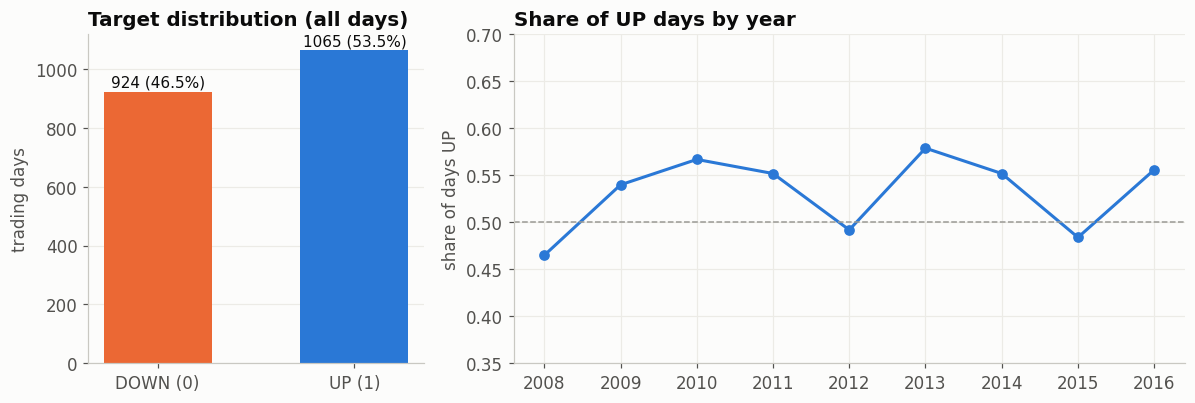

In [8]:
n_total = len(df)
up_rate = df.Label.mean()
by_year = df.groupby(df.Date.dt.year).Label.agg(days="size", up_rate="mean").round(3)
display(by_year.T)
RESULTS["dataset"] = {"n_days": n_total, "first": str(df.Date.min().date()), "last": str(df.Date.max().date()),
                      "up_rate_all": round(float(up_rate), 4), "missing_cells": missing}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2]})
cnt = df.Label.value_counts().sort_index()
bars = ax[0].bar(["DOWN (0)", "UP (1)"], cnt.values, color=[ORANGE, BLUE], width=0.55)
for b, v in zip(bars, cnt.values): ax[0].text(b.get_x()+b.get_width()/2, v+15, f"{v} ({v/n_total:.1%})", ha="center", fontsize=10)
ax[0].set_title("Target distribution (all days)"); ax[0].set_ylabel("trading days"); ax[0].grid(axis="x", visible=False)
ax[1].plot(by_year.index, by_year.up_rate, marker="o", color=BLUE, lw=2)
ax[1].axhline(0.5, color=GREY, ls="--", lw=1); ax[1].set_ylim(0.35, 0.7); ax[1].set_xticks(by_year.index)
ax[1].set_title("Share of UP days by year"); ax[1].set_ylabel("share of days UP")
plt.tight_layout(); savefig("01_target_distribution")

### Chronological split — never shuffled
| Set | Dates | Used for |
|---|---|---|
| **Train** (fit) | 2008-08-08 → 2013-12-31 | fitting models while we compare settings |
| **Validation** | 2014-01-01 → 2014-12-31 | choosing hyper-parameters and the preferred model (this is *inside* the 2008–2014 training period required by the brief) |
| **Final fit** | all of 2008–2014 | refit the chosen settings on the full training period |
| **Test** | 2015-01-01 → 2016-07-01 | **only** final reporting, all models on exactly the same days |

In [9]:
def split(frame):
    tr  = frame[frame.Date <  mp.VAL_START]
    va  = frame[(frame.Date >= mp.VAL_START) & (frame.Date <= mp.TRAIN_END)]
    te  = frame[frame.Date >= mp.TEST_START]
    return tr, va, te
tr, va, te = split(df)
for name, part in [("train (2008-2013)", tr), ("validation (2014)", va), ("test (2015-2016)", te)]:
    print(f"{name:18s} {part.Date.min().date()} -> {part.Date.max().date()}   {len(part):5d} days   UP rate {part.Label.mean():.3f}")
assert tr.Date.max() < va.Date.min() <= va.Date.max() < te.Date.min(), "splits must be strictly chronological"
print("OK: chronological, no overlap. Train+val (2008-2014):", len(tr)+len(va), "days | test:", len(te), "days")
RESULTS["split"] = {"train_days": len(tr), "val_days": len(va), "test_days": len(te), "trainval_days": len(tr)+len(va)}

train (2008-2013)  2008-08-08 -> 2013-12-31    1359 days   UP rate 0.540
validation (2014)  2014-01-02 -> 2014-12-31     252 days   UP rate 0.552
test (2015-2016)   2015-01-02 -> 2016-07-01     378 days   UP rate 0.508
OK: chronological, no overlap. Train+val (2008-2014): 1611 days | test: 378 days


### When is the prediction made? (look-ahead bias)
The dataset's headlines for date *D* are Reddit's top stories **on day D**, and the label says how the DJIA moved **on day D** (close vs. previous close). Reddit stories keep collecting votes and new ones appear during the US trading day, so some "day D headlines" may have been published **after** part of day D's market move. A model fed day-D headlines to predict day-D's move could therefore partly be reading the market's reaction, not forecasting it.

We handle this by running **both** versions and labelling them clearly:

* **Same-day (official brief setup):** headlines of day *D* → direction of day *D*. Matches the hackathon spec, but carries possible look-ahead bias.
* **Strict pre-market (our safer variant):** headlines of day *D−1* → direction of day *D*. The headlines are guaranteed to be older than the move we predict. This is the version a real forecaster could actually have used.

Market-history features (yesterday's direction) are legal in both versions because day *D−1*'s close is known before day *D* opens. Nothing from the future is used anywhere: features are computed **one day at a time** and the scaler/model are fit on training rows only.

## 2 · Sentiment analysis with VADER → daily features

**Why VADER?** It is a pretrained, rule-based sentiment model (NLTK) made for short social-media-style text: fast, free, no GPU, and every score can be explained to a judge. It gives each headline `neg`, `neu`, `pos` and a `compound` score from −1 (very negative) to +1 (very positive). FinBERT would understand finance wording better but needs a large model download and GPU time; we list it under *next steps* rather than claim a result we did not run.

For each day we aggregate its ≤25 headline scores into: mean, median, standard deviation, most-negative and most-positive headline, % negative (compound ≤ −0.05), % positive (≥ +0.05), and the mean of the `pos`/`neg`/`neu` components. We compute these twice — over **all** headlines (`all_*`) and over **financial** headlines only (`fin_*`, Part 4).

In [10]:
ft = mp.build_feature_table(df)          # one row per day; per-day computation only -> no cross-day leakage
ft = mp.add_market_history(ft)           # prev_dir, prev_up_rate5 (known before the day opens)
print(ft.shape); display(ft[["Date","Label","all_mean","all_std","all_min","all_pct_neg","fin_count","fin_mean","prev_dir"]].head(5).round(3))

(1989, 27)


,Date,Label,all_mean,all_std,all_min,all_pct_neg,fin_count,fin_mean,prev_dir
0,2008-08-08,0,-0.344,0.365,-0.926,0.64,1.0,0.202,NaN
1,2008-08-11,1,-0.166,0.394,-0.827,0.64,0.0,0.000,0.0
2,2008-08-12,0,-0.242,0.437,-0.859,0.48,1.0,-0.765,1.0
3,2008-08-13,0,-0.142,0.377,-0.807,0.52,0.0,0.000,0.0
4,2008-08-14,1,-0.198,0.464,-0.869,0.52,2.0,-0.612,0.0


headlines scored: 49718


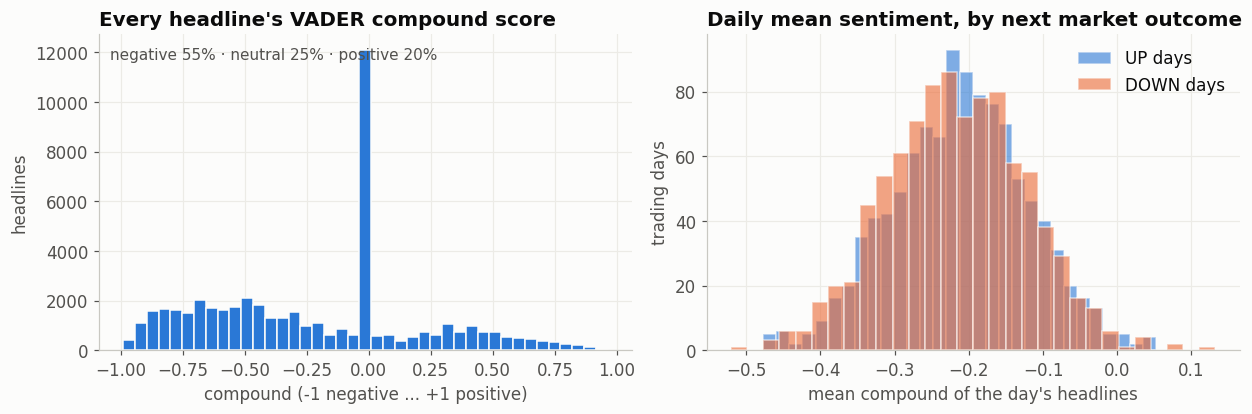

mean daily sentiment on UP days  : -0.2113
mean daily sentiment on DOWN days: -0.2168


In [11]:
# Distribution of sentiment: per-headline VADER compound + daily mean, up vs down days
all_scores = pd.concat([mp.score_headlines(mp.headlines_of(r)).assign(Label=r.Label) for _, r in df.iterrows()], ignore_index=True)
print("headlines scored:", len(all_scores))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].hist(all_scores.compound, bins=41, color=BLUE, edgecolor=SURF)
ax[0].set_title("Every headline's VADER compound score"); ax[0].set_xlabel("compound (-1 negative ... +1 positive)"); ax[0].set_ylabel("headlines")
share_neg = (all_scores.compound <= -0.05).mean(); share_pos = (all_scores.compound >= 0.05).mean()
ax[0].text(0.02, 0.92, f"negative {share_neg:.0%} · neutral {1-share_neg-share_pos:.0%} · positive {share_pos:.0%}", transform=ax[0].transAxes, color=MUTED, fontsize=10)
for lab, col, nm in [(1, BLUE, "UP days"), (0, ORANGE, "DOWN days")]:
    ax[1].hist(ft[ft.Label == lab].all_mean, bins=30, alpha=0.6, color=col, label=nm, edgecolor=SURF)
ax[1].set_title("Daily mean sentiment, by next market outcome"); ax[1].set_xlabel("mean compound of the day's headlines"); ax[1].set_ylabel("trading days"); ax[1].legend(frameon=False)
plt.tight_layout(); savefig("02_sentiment_distribution")
RESULTS["sentiment"] = {"headlines_scored": len(all_scores), "share_neg": round(float(share_neg), 4), "share_pos": round(float(share_pos), 4),
    "daily_mean_up": round(float(ft[ft.Label==1].all_mean.mean()), 4), "daily_mean_down": round(float(ft[ft.Label==0].all_mean.mean()), 4)}
print("mean daily sentiment on UP days  :", round(ft[ft.Label==1].all_mean.mean(), 4))
print("mean daily sentiment on DOWN days:", round(ft[ft.Label==0].all_mean.mean(), 4))

## 3 · Baselines and the first machine-learning models (Phase 1 / MVP)

**Baseline A — always UP.** Pure majority-class guess. **Baseline B — same as previous trading day.** It looks at the market (yesterday's label) and nothing else. For the first test day we use the last training day's label, which is legitimately known.

**Model 1 — Logistic Regression** (why: simple, interpretable, hard to overfit with ~10 features). **Model 2 — Random Forest** (why: can find non-linear interactions between sentiment features; tests whether LR is too simple). Both use the daily sentiment features of *all* headlines. Hyper-parameters are chosen on the **validation year**, then the model is refit on all of 2008–2014 and evaluated once on 2015–2016.

In [12]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n; c = p + z*z/(2*n); w = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return (c - w)/d, (c + w)/d

def mcnemar_exact(correct_a, correct_b):
    # exact paired test: on days where A and B disagree, is one right more often than chance?
    a = np.asarray(correct_a, bool); b = np.asarray(correct_b, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    return 1.0 if n10 + n01 == 0 else stats.binomtest(n10, n10 + n01, 0.5).pvalue

def prf(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[1], average=None, zero_division=0)
    return dict(accuracy=float(accuracy_score(y, p)), precision_up=float(pr[0]), recall_up=float(rc[0]), f1_up=float(f1[0]))

def make_model(kind, p):
    if kind == "lr": return make_pipeline(StandardScaler(), LogisticRegression(C=p, max_iter=3000))
    return RandomForestClassifier(n_estimators=300, max_depth=p[0], min_samples_leaf=p[1], random_state=SEED, n_jobs=-1)
GRIDS = {"lr": [0.001, 0.01, 0.1, 1.0, 10.0], "rf": [(d, l) for d in (2, 3, 5, 8) for l in (10, 30)]}

def prepare(cols, lag_news):
    f = ft.copy()
    if lag_news: f = mp.lag_news(f, [c for c in cols if c.startswith(("all_", "fin_"))])
    return f.dropna(subset=cols).reset_index(drop=True)

def fit_select(cols, kind, lag_news=False):
    # choose hyper-parameters on VALIDATION (2014), refit on all of 2008-2014, evaluate ONCE on TEST.
    f = prepare(cols, lag_news); tr_, va_, te_ = split(f)
    best = None
    for p in GRIDS[kind]:
        m = make_model(kind, p).fit(tr_[cols], tr_.Label); a = m.score(va_[cols], va_.Label)
        if best is None or a > best[0]: best = (a, p)
    val_acc, p = best
    full = pd.concat([tr_, va_]); m = make_model(kind, p).fit(full[cols], full.Label)
    return dict(model=m, params=p, val_acc=float(val_acc), te=te_, cols=cols,
                pred=m.predict(te_[cols]), proba=m.predict_proba(te_[cols])[:, 1])

# ---- baselines on the test days ----
te_all = ft[ft.Date >= mp.TEST_START].copy()
y_te = te_all.Label.values
pred_up = np.ones(len(te_all), int)
pred_prev = ft.Label.shift(1)[te_all.index].astype(int).values
base = {"Always UP": pred_up, "Previous day": pred_prev}
BASE_RES = {k: prf(y_te, v) for k, v in base.items()}
print(f"Evaluated test days: {len(te_all)}  ({te_all.Date.min().date()} -> {te_all.Date.max().date()})")
display(pd.DataFrame(BASE_RES).T.round(3))

Evaluated test days: 378  (2015-01-02 -> 2016-07-01)


,accuracy,precision_up,recall_up,f1_up
Always UP,0.508,0.508,1.000,0.674
Previous day,0.458,0.466,0.464,0.465


In [13]:
# ---- Model 1 & 2 on ALL-headline sentiment (same-day setup as in the brief) ----
ALL_COLS = mp.feature_columns("all")
primary = {k: fit_select(ALL_COLS, k) for k in ("lr", "rf")}
rows = []
for k, nm in (("lr", "Logistic Regression"), ("rf", "Random Forest")):
    r = primary[k]; m = prf(r["te"].Label.values, r["pred"])
    rows.append({"model": nm, "chosen_params": str(r["params"]), "VALIDATION acc (2014)": r["val_acc"], "TEST acc (2015-16)": m["accuracy"],
                 "precision(UP)": m["precision_up"], "recall(UP)": m["recall_up"], "F1(UP)": m["f1_up"], "test days": len(r["te"])})
primary_tbl = pd.DataFrame(rows).set_index("model"); display(primary_tbl.round(3))
best_kind = max(primary, key=lambda k: primary[k]["val_acc"])      # preferred model picked on VALIDATION only
SEL = primary[best_kind]
print(f"Preferred model (chosen by validation accuracy, not test): {'Logistic Regression' if best_kind=='lr' else 'Random Forest'}  params={SEL['params']}")

,chosen_params,VALIDATION acc (2014),TEST acc (2015-16),precision(UP),recall(UP),F1(UP),test days
model,,,,,,,
Logistic Regression,0.1,0.567,0.487,0.497,0.859,0.630,378
Random Forest,"(5, 10)",0.571,0.460,0.480,0.755,0.587,378


Preferred model (chosen by validation accuracy, not test): Random Forest  params=(5, 10)


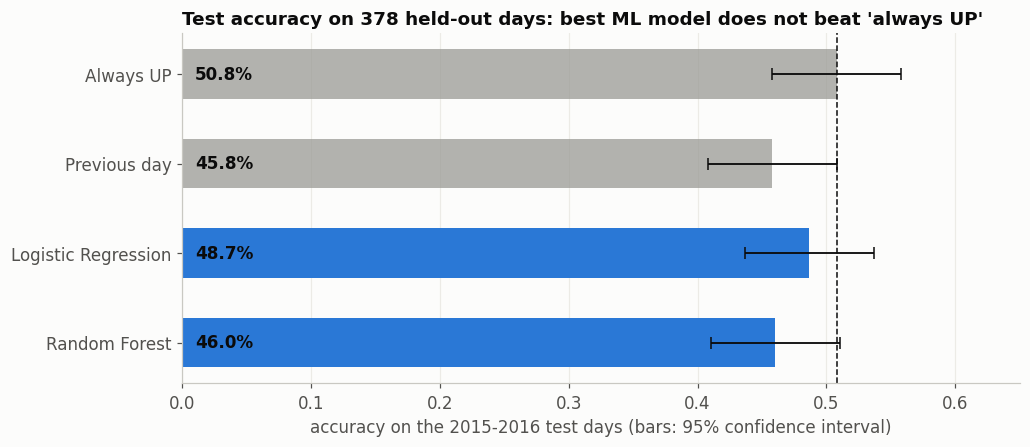

,test accuracy,95% CI low,95% CI high,p-value vs Always UP (exact paired test)
Always UP,0.508,0.458,0.558,1.000
Previous day,0.458,0.408,0.508,0.188
Logistic Regression,0.487,0.437,0.537,0.302
Random Forest,0.460,0.411,0.511,0.050


In [14]:
# ---- Test-set accuracy comparison with 95% confidence intervals ----
names = ["Always UP", "Previous day", "Logistic Regression", "Random Forest"]
preds = {"Always UP": pred_up, "Previous day": pred_prev, "Logistic Regression": primary["lr"]["pred"], "Random Forest": primary["rf"]["pred"]}
n = len(y_te); acc = {k: float((v == y_te).mean()) for k, v in preds.items()}
ci = {k: wilson(int((v == y_te).sum()), n) for k, v in preds.items()}
pvals = {k: mcnemar_exact(preds[k] == y_te, pred_up == y_te) for k in names}

fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols_ = [GREY, GREY, BLUE, BLUE]; ypos = np.arange(len(names))[::-1]
for y, k, c in zip(ypos, names, cols_):
    ax.barh(y, acc[k], color=c, height=0.55, alpha=1 if c == BLUE else .75)
    ax.errorbar(acc[k], y, xerr=[[acc[k]-ci[k][0]], [ci[k][1]-acc[k]]], color=INK, capsize=4, lw=1.2)
    ax.text(0.01, y, f"{acc[k]:.1%}", va="center", color=INK, fontweight="bold", fontsize=11)
ax.axvline(acc["Always UP"], color=INK, ls="--", lw=1); ax.set_yticks(ypos); ax.set_yticklabels(names); ax.set_xlim(0, 0.65)
ax.set_xlabel("accuracy on the 2015-2016 test days (bars: 95% confidence interval)"); ax.grid(axis="y", visible=False)
best_ml = max(acc["Logistic Regression"], acc["Random Forest"])
ax.set_title(f"Test accuracy on {n} held-out days: " + ("best ML model " + ("does not beat" if best_ml <= acc["Always UP"] else "beats") + " 'always UP'"), fontsize=12); plt.tight_layout(); savefig("03_model_accuracy_comparison")
RESULTS["headline_models"] = {k: {"test_acc": acc[k], "ci95": ci[k], "p_vs_always_up": pvals[k]} for k in names}
RESULTS["primary"] = {k: {"params": str(primary[k]["params"]), "val_acc": primary[k]["val_acc"], **prf(primary[k]["te"].Label.values, primary[k]["pred"])} for k in primary}
RESULTS["preferred_model"] = best_kind; RESULTS["baselines"] = BASE_RES; RESULTS["n_test_days"] = n
display(pd.DataFrame({"test accuracy": acc, "95% CI low": {k: ci[k][0] for k in names}, "95% CI high": {k: ci[k][1] for k in names},
                      "p-value vs Always UP (exact paired test)": pvals}).round(3))

In [15]:
display(Markdown(f'''**Reading the result.** On the {n} test days, *Always UP* scores **{acc["Always UP"]:.1%}**, *Previous day* **{acc["Previous day"]:.1%}**,
Logistic Regression **{acc["Logistic Regression"]:.1%}** and Random Forest **{acc["Random Forest"]:.1%}**. With only {n} days, a 95% confidence interval is roughly ±5 points wide,
so differences of a couple of points are indistinguishable from luck. Validation accuracies (2014) looked a bit better than test accuracies — a normal symptom of choosing the best of several settings on a small set.'''))

**Reading the result.** On the 378 test days, *Always UP* scores **50.8%**, *Previous day* **45.8%**,
Logistic Regression **48.7%** and Random Forest **46.0%**. With only 378 days, a 95% confidence interval is roughly ±5 points wide,
so differences of a couple of points are indistinguishable from luck. Validation accuracies (2014) looked a bit better than test accuracies — a normal symptom of choosing the best of several settings on a small set.

## 4 · Original research: do *financial* headlines predict better than *general* world news?
The dataset is **world** news, so most headlines are about wars, politics or crime, not markets. Our hypothesis: a model that listens only to **financial / economic headlines** might find more signal. We did **not** assume this is true — we test it.

**Method (reproducible and transparent).** A keyword/regular-expression classifier (`marketpulse.py → FIN_CATEGORIES`) tags a headline as financial if it matches any of six categories: *Fed & interest rates*, *inflation & jobs*, *economic growth*, *banking & markets*, *corporate earnings*, *trade & economic policy*. It is deliberately simple — every rule can be read and explained — but it is **not** perfect (see limitations). Group **A** = sentiment over all headlines; Group **B** = sentiment over financial headlines only (plus how many there were).

headlines: 49,718 | tagged financial: 4,831 (9.7%) | days with zero financial headlines: 194 of 1989


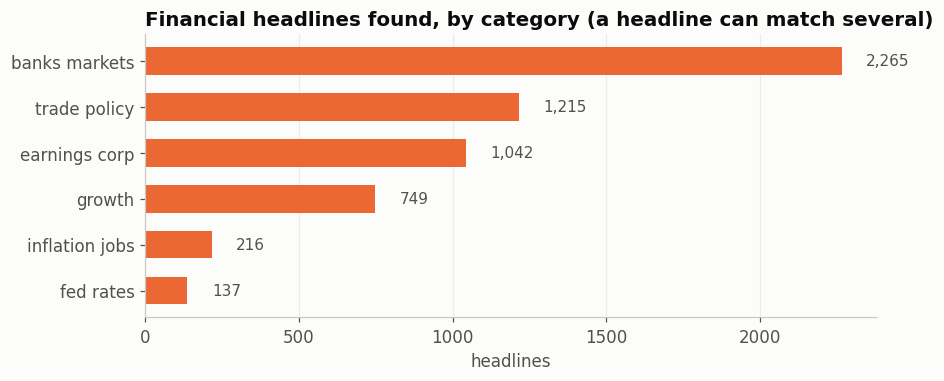


Spot-check: 3 random headlines the filter tagged per category (read them yourself - the filter is not perfect):
  [fed_rates] Six Giant Banks Made $51bil last year; The other 980 Lost Money; the proprietary trading operations of an olig
  [fed_rates] Icelands PM to Sack Central Bank Governors
  [fed_rates] Bank of England director: Occupy was right
  [inflation_jobs] Europe's Youth Unemployment Crisis In One Grim Map
  [inflation_jobs] Tories say earning in the 99.9th percentile is "chicken feed", while out in the real world the average debt is
  [inflation_jobs] Australia raises the minimum wage to us $16.50 per hour... any young people in the USA interested in a "workin
  [growth] Gulf countries face water shortages. The region's rapid population growth and accelerated socio-economic devel
  [growth] The Digital Economy Bill has betrayed the young: \r Positive engagement with the digital generation \r interes
  [growth] The German economy is rapidly improving, with many manufacturer

In [16]:
cat_counts = {c: 0 for c in mp.FIN_CATEGORIES}; total_h = 0; fin_h = 0; examples = {c: [] for c in mp.FIN_CATEGORIES}
rng = np.random.RandomState(SEED)
for _, r in df.iterrows():
    for h in mp.headlines_of(r):
        total_h += 1; cats = mp.fin_categories(h)
        if cats: fin_h += 1
        for c in cats:
            cat_counts[c] += 1
            if len(examples[c]) < 400: examples[c].append(h)
print(f"headlines: {total_h:,} | tagged financial: {fin_h:,} ({fin_h/total_h:.1%}) | days with zero financial headlines: {(ft.fin_count==0).sum()} of {len(ft)}")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
order = sorted(cat_counts, key=cat_counts.get)
ax.barh([c.replace('_', ' ') for c in order], [cat_counts[c] for c in order], color=ORANGE, height=0.6)
for i, c in enumerate(order): ax.text(cat_counts[c] + 80, i, f"{cat_counts[c]:,}", va="center", color=MUTED, fontsize=10)
ax.set_title("Financial headlines found, by category (a headline can match several)"); ax.set_xlabel("headlines"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("04_financial_categories")
RESULTS["fin_filter"] = {"headlines": total_h, "financial": fin_h, "share": fin_h/total_h, "days_with_zero_fin": int((ft.fin_count==0).sum()), "category_counts": cat_counts}
print("\nSpot-check: 3 random headlines the filter tagged per category (read them yourself - the filter is not perfect):")
for c in mp.FIN_CATEGORIES:
    for h in rng.choice(examples[c], 3, replace=False): print(f"  [{c}] {h[:110]}")

In [17]:
# ---- Experiment grid: every feature set x model x timing, hyper-parameters chosen on validation, one test evaluation each ----
MKT = ["prev_dir", "prev_up_rate5"]
FEATSETS = {"All news": mp.feature_columns("all"), "Financial news only": mp.feature_columns("fin"),
            "All + Financial": mp.feature_columns("both"), "Market history only (no news)": MKT,
            "All news + market history": mp.feature_columns("all") + MKT, "Financial + market history": mp.feature_columns("fin") + MKT}
grid_rows, GRID = [], {}
for timing, lag in (("same-day headlines", False), ("previous-day headlines", True)):
    for fs, cols in FEATSETS.items():
        for kind in ("lr", "rf"):
            if fs.startswith("Market history only") and lag: continue   # no news inside, timing is irrelevant
            r = fit_select(cols, kind, lag); yt = r["te"].Label.values
            ok = int((r["pred"] == yt).sum()); lo, hi = wilson(ok, len(yt))
            ref_up = float((yt == 1).mean())
            p = mcnemar_exact(r["pred"] == yt, np.ones(len(yt)) == yt)
            GRID[(timing, fs, kind)] = r
            grid_rows.append({"timing": timing, "features": fs, "model": "LogReg" if kind == "lr" else "RandForest", "val_acc": r["val_acc"],
                              "test_acc": ok/len(yt), "ci_low": lo, "ci_high": hi, "always_up_on_same_days": ref_up, "test_days": len(yt), "p_vs_always_up": p})
G = pd.DataFrame(grid_rows)
display(G.round(3).style.format({c: "{:.3f}" for c in ["val_acc","test_acc","ci_low","ci_high","always_up_on_same_days","p_vs_always_up"]}))
RESULTS["grid"] = G.round(4).to_dict(orient="records")
better = (G.test_acc > G.always_up_on_same_days); sig = (G.p_vs_always_up < 0.05)
print(f"\nOf {len(G)} experiments: {better.sum()} scored above 'Always UP' on the same test days, {(~better).sum()} scored at or below it.")
print(f"Differences with p<0.05 (either direction): {sig.sum()} -> {(sig & better).sum()} better than Always UP, {(sig & ~better).sum()} WORSE than Always UP.")
print(f"With {len(G)} comparisons, ~{0.05*len(G):.1f} p<0.05 results would appear by chance alone, so a lone 'win' is not evidence.")
RESULTS["grid_summary"] = {"n": len(G), "above": int(better.sum()), "sig_better": int((sig & better).sum()), "sig_worse": int((sig & ~better).sum())}

,timing,features,model,val_acc,test_acc,ci_low,ci_high,always_up_on_same_days,test_days,p_vs_always_up
0,same-day headlines,All news,LogReg,0.567,0.487,0.437,0.537,0.508,378,0.302
1,same-day headlines,All news,RandForest,0.571,0.460,0.411,0.511,0.508,378,0.050
2,same-day headlines,Financial news only,LogReg,0.548,0.511,0.460,0.561,0.508,378,1.000
3,same-day headlines,Financial news only,RandForest,0.548,0.505,0.455,0.555,0.508,378,1.000
4,same-day headlines,All + Financial,LogReg,0.556,0.503,0.452,0.553,0.508,378,0.824
5,same-day headlines,All + Financial,RandForest,0.571,0.460,0.411,0.511,0.508,378,0.044
6,same-day headlines,Market history only (no news),LogReg,0.563,0.492,0.442,0.542,0.508,378,0.504
7,same-day headlines,Market history only (no news),RandForest,0.563,0.489,0.439,0.540,0.508,378,0.360
8,same-day headlines,All news + market history,LogReg,0.571,0.505,0.455,0.555,0.508,378,1.000
9,same-day headlines,All news + market history,RandForest,0.563,0.508,0.458,0.558,0.508,378,1.000



Of 22 experiments: 5 scored above 'Always UP' on the same test days, 17 scored at or below it.
Differences with p<0.05 (either direction): 1 -> 0 better than Always UP, 1 WORSE than Always UP.
With 22 comparisons, ~1.1 p<0.05 results would appear by chance alone, so a lone 'win' is not evidence.


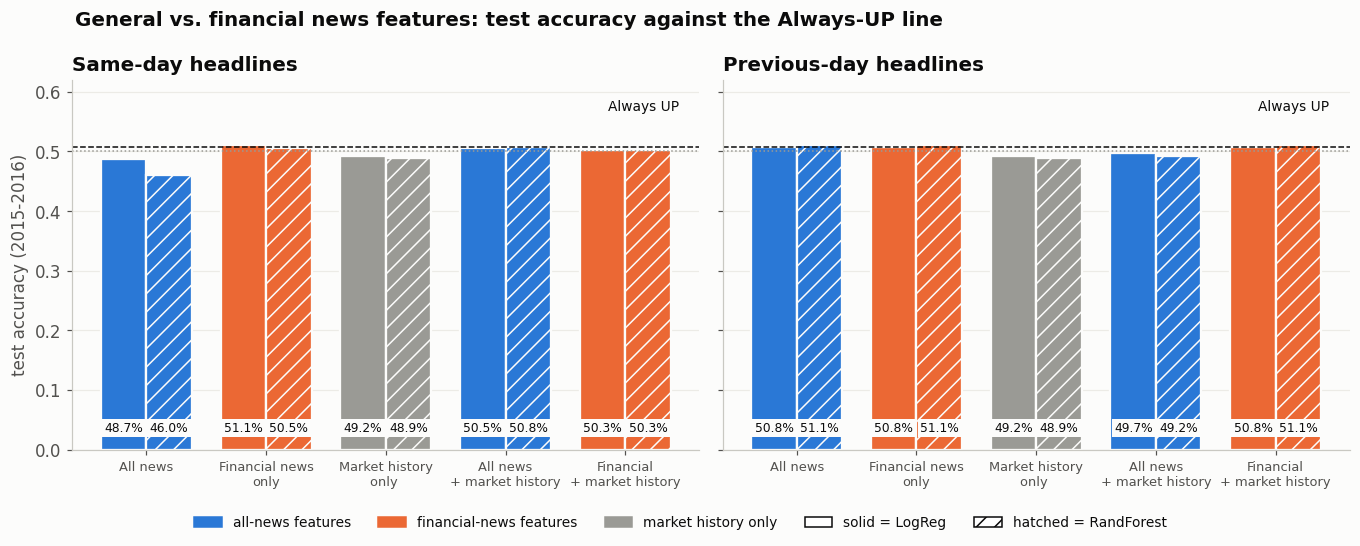

In [18]:
# ---- Chart: general news vs financial news (+ market-history controls) ----
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
show = ["All news", "Financial news only", "Market history only (no news)", "All news + market history", "Financial + market history"]
for ax, timing in zip(axes, ["same-day headlines", "previous-day headlines"]):
    sub = G[(G.timing == timing) | (G.features == "Market history only (no news)")]
    x = np.arange(len(show)); w = 0.38
    for j, (mdl, hatch) in enumerate([("LogReg", ""), ("RandForest", "//")]):
        v = [sub[(sub.features == f) & (sub.model == mdl)].test_acc.values[0] for f in show]
        col = [ORANGE if "Financial" in f else (GREY if "Market history only" in f else BLUE) for f in show]
        ax.bar(x + (j-.5)*w, v, w, color=col, hatch=hatch, edgecolor=SURF, linewidth=1.5)
        for xi, vi in zip(x + (j-.5)*w, v): ax.text(xi, 0.03, f"{vi:.1%}", ha="center", fontsize=8, color=INK, bbox=dict(fc=SURF, ec="none", pad=1.5))
    ax.axhline(acc["Always UP"], color=INK, ls="--", lw=1); ax.text(len(show)-0.55, acc["Always UP"]+0.06, "Always UP", ha="right", fontsize=9, color=INK)
    ax.axhline(0.5, color=GREY, ls=":", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([f.replace(" + ", "\n+ ").replace(" only", "\nonly").replace("(no news)", "") for f in show], fontsize=8.5)
    ax.set_ylim(0, 0.62); ax.set_title(timing.capitalize()); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("test accuracy (2015-2016)")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=BLUE, label="all-news features"), Patch(color=ORANGE, label="financial-news features"), Patch(color=GREY, label="market history only"),
                    Patch(facecolor="white", edgecolor=INK, label="solid = LogReg"), Patch(facecolor="white", edgecolor=INK, hatch="//", label="hatched = RandForest")],
           ncol=5, loc="lower center", frameon=False, bbox_to_anchor=(0.5, -0.07), fontsize=9)
fig.suptitle("General vs. financial news features: test accuracy against the Always-UP line", x=0.06, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); savefig("05_general_vs_financial")

### 4a · More robust evidence: expanding-window evaluation (2010-2016)
A single 378-day test set is small. To get more statistical power for the "financial vs. general" question, we repeat the experiment for **every year from 2010 to 2016**: train on all earlier years, test on that year (always chronological, hyper-parameters fixed at LR `C=0.1`, no tuning at all, so nothing can leak). This is an *extra* robustness check — the official result remains the 2015-2016 test above.

In [19]:
def expanding(cols, lag, C=0.1):
    f = prepare(cols, lag); out = []
    for yr in range(2010, 2017):
        trn, tst = f[f.Date.dt.year < yr], f[f.Date.dt.year == yr]
        m = make_model("lr", C).fit(trn[cols], trn.Label); p = m.predict(tst[cols]); out.append((yr, tst.Label.values, p))
    return out
EXP = {}
for lag in (False, True):
    for nm, cols in [("All news", mp.feature_columns("all")), ("Financial news only", mp.feature_columns("fin")), ("Market history only", MKT)]:
        if nm == "Market history only" and lag: continue
        res = expanding(cols, lag); y = np.concatenate([r[1] for r in res]); p = np.concatenate([r[2] for r in res])
        EXP[(lag, nm)] = dict(per_year={r[0]: float((r[1] == r[2]).mean()) for r in res}, y=y, p=p)
yall = EXP[(False, "All news")]["y"]
rows = []
for (lag, nm), r in EXP.items():
    ok = int((r["p"] == r["y"]).sum()); lo, hi = wilson(ok, len(r["y"]))
    rows.append({"timing": "previous-day" if lag else "same-day", "features": nm, "pooled_acc_2010_16": ok/len(r["y"]), "ci_low": lo, "ci_high": hi,
                 "always_up_acc": float(r["y"].mean()), "days": len(r["y"]), "p_vs_always_up": mcnemar_exact(r["p"] == r["y"], r["y"] == 1)})
EXPT = pd.DataFrame(rows); display(EXPT.round(3))
pa = pd.DataFrame({f"{'prev' if l else 'same'}-day | {n_}": r["per_year"] for (l, n_), r in EXP.items()}).T
up_by_year = pd.Series({yr: float(ft[ft.Date.dt.year == yr].Label.mean()) for yr in range(2010, 2017)}, name="Always UP")
display(pd.concat([pa, up_by_year.to_frame().T]).round(3))
f_same, a_same = EXP[(False, "Financial news only")], EXP[(False, "All news")]
p_fin_vs_all = mcnemar_exact(f_same["p"] == f_same["y"], a_same["p"] == a_same["y"])
RESULTS["expanding"] = {"table": EXPT.round(4).to_dict(orient="records"), "per_year": {f"{'prev' if l else 'same'}|{n_}": r["per_year"] for (l, n_), r in EXP.items()},
                        "p_fin_vs_all_same_day": p_fin_vs_all}
print("Paired test, financial-only vs all-news model (same-day, 2010-2016):  p =", round(p_fin_vs_all, 3))

,timing,features,pooled_acc_2010_16,ci_low,ci_high,always_up_acc,days,p_vs_always_up
0,same-day,All news,0.531,0.507,0.555,0.539,1636,0.534
1,same-day,Financial news only,0.531,0.507,0.555,0.539,1636,0.563
2,same-day,Market history only,0.532,0.508,0.556,0.539,1636,0.465
3,previous-day,All news,0.523,0.499,0.547,0.539,1636,0.157
4,previous-day,Financial news only,0.501,0.476,0.525,0.539,1636,0.001


,2010,2011,2012,2013,2014,2015,2016
same-day | All news,0.563,0.536,0.484,0.563,0.567,0.456,0.563
same-day | Financial news only,0.548,0.528,0.508,0.575,0.528,0.520,0.492
same-day | Market history only,0.575,0.532,0.492,0.571,0.552,0.468,0.540
prev-day | All news,0.544,0.504,0.524,0.532,0.532,0.484,0.563
prev-day | Financial news only,0.516,0.480,0.460,0.472,0.556,0.488,0.563
Always UP,0.567,0.552,0.492,0.579,0.552,0.484,0.556


Paired test, financial-only vs all-news model (same-day, 2010-2016):  p = 1.0


### 4b · Does negative news carry more information? Do high-sentiment days work better? Does yesterday's direction help?

In [20]:
# (1) Negative vs positive: use only the negative-tone features or only the positive-tone features
NEG = ["all_pct_neg", "all_mean_neg", "all_min"]; POS = ["all_pct_pos", "all_mean_pos", "all_max"]
FNEG = ["fin_pct_neg", "fin_mean_neg", "fin_min"]; FPOS = ["fin_pct_pos", "fin_mean_pos", "fin_max"]
rows = []
for nm, cols in [("negative-tone features (all news)", NEG), ("positive-tone features (all news)", POS), ("negative-tone (financial)", FNEG), ("positive-tone (financial)", FPOS)]:
    r = fit_select(cols, "lr"); yt = r["te"].Label.values; ok = int((r["pred"] == yt).sum()); lo, hi = wilson(ok, len(yt))
    rows.append({"features": nm, "val_acc": r["val_acc"], "test_acc": ok/len(yt), "ci_low": lo, "ci_high": hi})
NP = pd.DataFrame(rows); display(NP.round(3)); RESULTS["neg_vs_pos"] = NP.round(4).to_dict(orient="records")

# (2) Univariate look at the TRAINING period only: correlation of each feature with "market went UP"
trv = ft[ft.Date <= mp.TRAIN_END]
cr = []
for c in mp.feature_columns("both"):
    r_, p_ = stats.pointbiserialr(trv.Label, trv[c]); cr.append((c, r_, p_))
CR = pd.DataFrame(cr, columns=["feature", "corr_with_UP", "p_value"]).sort_values("p_value").head(6)
print(f"\nStrongest single-feature correlations with UP in the training period (2008-2014; {len(mp.feature_columns('both'))} features tested, so a few small p-values are expected by chance):")
display(CR.round(4)); print(f"Bonferroni-corrected significance level for 22 tests: p < {0.05/22:.4f}.  Even the best correlation explains <1% of day-to-day variation (r^2 = {CR.corr_with_UP.iloc[0]**2:.4f}).")
RESULTS["top_train_correlations"] = CR.round(4).to_dict(orient="records")

,features,val_acc,test_acc,ci_low,ci_high
0,negative-tone features (all news),0.571,0.481,0.432,0.532
1,positive-tone features (all news),0.552,0.511,0.460,0.561
2,negative-tone (financial),0.552,0.508,0.458,0.558
3,positive-tone (financial),0.552,0.508,0.458,0.558



Strongest single-feature correlations with UP in the training period (2008-2014; 22 features tested, so a few small p-values are expected by chance):


,feature,corr_with_UP,p_value
5,all_pct_neg,-0.0768,0.0020
0,all_mean,0.0715,0.0041
1,all_median,0.0658,0.0083
7,all_mean_pos,0.0569,0.0224
8,all_mean_neg,-0.0536,0.0313
6,all_pct_pos,0.0515,0.0387


Bonferroni-corrected significance level for 22 tests: p < 0.0023.  Even the best correlation explains <1% of day-to-day variation (r^2 = 0.0059).


In [21]:
# (3) High-sentiment days: are predictions more accurate when the day's news is unusually positive/negative?
thr = trv.all_mean.abs().quantile(0.75)          # threshold learned from training data only
rows = []
for kind in ("lr", "rf"):
    r = primary[kind]; t = r["te"]; hi_mask = (t.all_mean.abs() >= thr).values; yt = t.Label.values; ok = (r["pred"] == yt)
    for nm, mk in (("high-|sentiment| days", hi_mask), ("other days", ~hi_mask)):
        k = int(ok[mk].sum()); nn = int(mk.sum()); lo, hi = wilson(k, nn)
        rows.append({"model": kind.upper(), "days": nm, "n_days": nn, "model_acc": k/nn, "ci_low": lo, "ci_high": hi, "always_up_acc": float(yt[mk].mean())})
HS = pd.DataFrame(rows); print(f"High-sentiment = top 25% of |daily mean compound| in training data (|mean| >= {thr:.3f})"); display(HS.round(3))
RESULTS["high_sentiment"] = {"threshold": float(thr), "table": HS.round(4).to_dict(orient="records")}

High-sentiment = top 25% of |daily mean compound| in training data (|mean| >= 0.282)


,model,days,n_days,model_acc,ci_low,ci_high,always_up_acc
0,LR,high-|sentiment| days,61,0.475,0.355,0.598,0.574
1,LR,other days,317,0.489,0.434,0.544,0.495
2,RF,high-|sentiment| days,61,0.443,0.325,0.567,0.574
3,RF,other days,317,0.464,0.410,0.519,0.495


In [22]:
# (4) Does adding yesterday's market direction help?  (from the grid; test accuracy, same-day headlines)
ctrl = G[(G.timing.isin(["same-day headlines"])) | (G.features == "Market history only (no news)")].pivot_table(index="features", columns="model", values="test_acc")
display(ctrl.round(3)); RESULTS["prev_dir_effect"] = ctrl.round(4).to_dict()

model,LogReg,RandForest
features,,
All + Financial,0.503,0.460
All news,0.487,0.460
All news + market history,0.505,0.508
Financial + market history,0.503,0.503
Financial news only,0.511,0.505
Market history only (no news),0.492,0.489


## 5 · Evaluation of the preferred model, visual checks and error analysis

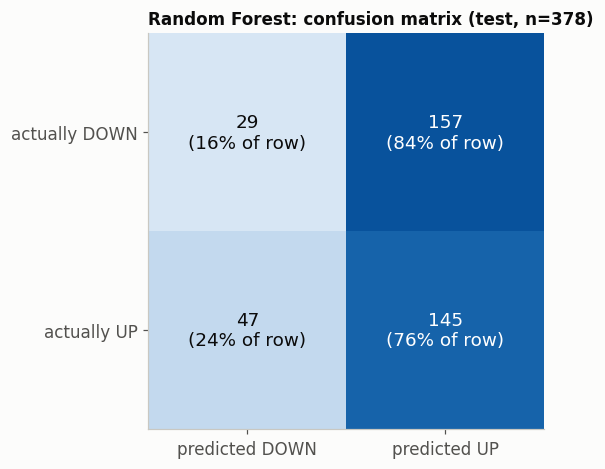

True DOWN predicted DOWN: 29 | wrongly predicted UP (false alarm 'UP'): 157 | wrongly predicted DOWN (missed rise): 47 | True UP predicted UP: 145
{'accuracy': 0.46, 'precision_up': 0.48, 'recall_up': 0.755, 'f1_up': 0.587} | evaluated days: 378
Model predicts UP on 79.9% of days; actual UP share 50.8%
Predicted P(up) ranges 0.40-0.69 (std 0.054); training base rate was 0.54 -> the model mostly leans on the base rate and makes only small adjustments.


In [23]:
t = SEL["te"].reset_index(drop=True); yt = t.Label.values; pp = SEL["pred"]; pr = SEL["proba"]
cm = confusion_matrix(yt, pp, labels=[0, 1]); m_sel = prf(yt, pp)
nm_sel = "Logistic Regression" if best_kind == "lr" else "Random Forest"
fig, ax = plt.subplots(figsize=(5.2, 4.4)); ax.grid(False)
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max()*1.15)
for i in range(2):
    for j in range(2): ax.text(j, i, f"{cm[i,j]}\n({cm[i,j]/cm[i].sum():.0%} of row)", ha="center", va="center", color="white" if cm[i,j] > cm.max()*.55 else INK, fontsize=12)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["predicted DOWN", "predicted UP"]); ax.set_yticklabels(["actually DOWN", "actually UP"])
ax.set_title(f"{nm_sel}: confusion matrix (test, n={len(yt)})", fontsize=11); plt.tight_layout(); savefig("06_confusion_matrix")
tn, fp, fn, tp = cm.ravel()
print(f"True DOWN predicted DOWN: {tn} | wrongly predicted UP (false alarm 'UP'): {fp} | wrongly predicted DOWN (missed rise): {fn} | True UP predicted UP: {tp}")
print({k: round(v, 3) for k, v in m_sel.items()}, "| evaluated days:", len(yt))
print(f"Model predicts UP on {pp.mean():.1%} of days; actual UP share {yt.mean():.1%}")
print(f"Predicted P(up) ranges {pr.min():.2f}-{pr.max():.2f} (std {pr.std():.3f}); training base rate was {ft[ft.Date<=mp.TRAIN_END].Label.mean():.2f} -> the model mostly leans on the base rate and makes only small adjustments.")
RESULTS["selected"] = {"name": nm_sel, "params": str(SEL["params"]), "val_acc": SEL["val_acc"], **m_sel, "confusion": cm.tolist(), "pred_up_share": float(pp.mean())}

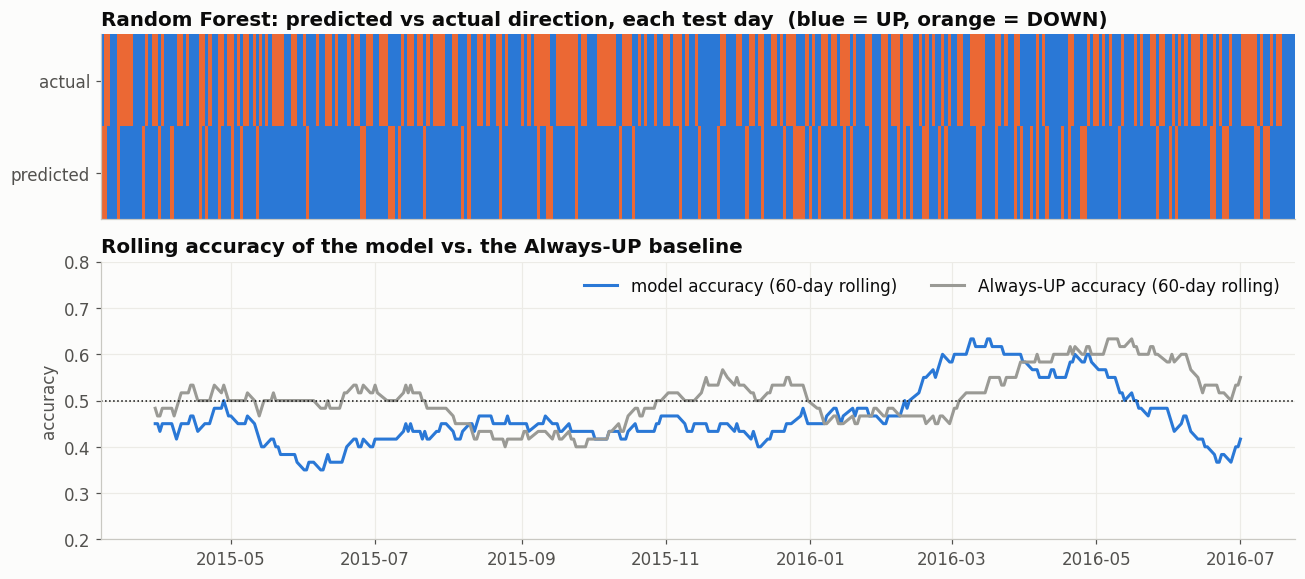

In [24]:
# Predicted vs actual direction over time, plus rolling accuracy
fig, ax = plt.subplots(2, 1, figsize=(12, 5.4), gridspec_kw={"height_ratios": [1, 1.5]}, sharex=False)
strip = np.vstack([yt, pp]); from matplotlib.colors import ListedColormap
ax[0].imshow(strip, aspect="auto", cmap=ListedColormap([ORANGE, BLUE]), interpolation="nearest", extent=[0, len(yt), 2, 0]); ax[0].grid(False)
ax[0].set_yticks([0.5, 1.5]); ax[0].set_yticklabels(["actual", "predicted"]); ax[0].set_xticks([])
ax[0].set_title(f"{nm_sel}: predicted vs actual direction, each test day  (blue = UP, orange = DOWN)")
roll = pd.Series((yt == pp).astype(float)).rolling(60).mean()
ax[1].plot(t.Date, roll, color=BLUE, lw=2, label="model accuracy (60-day rolling)")
ax[1].plot(t.Date, pd.Series(yt).rolling(60).mean(), color=GREY, lw=2, label="Always-UP accuracy (60-day rolling)")
ax[1].axhline(0.5, color=INK, ls=":", lw=1); ax[1].set_ylim(0.2, 0.8); ax[1].set_ylabel("accuracy"); ax[1].legend(frameon=False, loc="upper right", ncol=2)
ax[1].set_title("Rolling accuracy of the model vs. the Always-UP baseline")
plt.tight_layout(); savefig("07_predicted_vs_actual")

In [25]:
# A real prediction example (a correct, confidently-predicted test day) - with the headlines the model saw
def show_day(i, title):
    d = t.iloc[i]; hs = mp.headlines_of(df.loc[df.Date == d.Date].iloc[0]); sc = mp.score_headlines(hs)
    print(f"{title}\n  Date: {d.Date.date()} | actual: {'UP' if d.Label else 'DOWN'} | predicted: {'UP' if pp[i] else 'DOWN'} | model P(up)={pr[i]:.2f}")
    print(f"  daily mean sentiment {d.all_mean:+.3f} | % negative headlines {d.all_pct_neg:.0%} | financial headlines found: {int(d.fin_count)}")
    order = np.argsort(sc.compound.values)
    print("  most negative:", *[f"\n     ({sc.compound.values[j]:+.2f}) {hs[j][:105]}" for j in order[:2]])
    print("  most positive:", *[f"\n     ({sc.compound.values[j]:+.2f}) {hs[j][:105]}" for j in order[::-1][:2]])
right = np.where(pp == yt)[0]; i_ok = right[np.argmax(np.abs(pr[right] - 0.5))]
show_day(i_ok, "REAL PREDICTION EXAMPLE (correct)")

REAL PREDICTION EXAMPLE (correct)
  Date: 2015-09-30 | actual: UP | predicted: UP | model P(up)=0.69
  daily mean sentiment -0.109 | % negative headlines 36% | financial headlines found: 1
  most negative: 
     (-0.98) Norwegian terrorist and mass murderer, Anders Behring Breivik, who killed 77 people in 2011, pledges to h 
     (-0.78) An Iranian man who was on death row for allegedly insulting the prophet Muhammad has had his sentence com
  most positive: 
     (+0.86) Germany has translated the first 20 articles of the country's constitution, which outline basic rights li 
     (+0.42) The Russian parliament on Wednesday unanimously granted President Vladimir Putin the right to deploy the 


In [26]:
# Failure analysis: the 4 most confident WRONG predictions
wrong = np.where(pp != yt)[0]; worst = wrong[np.argsort(-np.abs(pr[wrong] - 0.5))][:4]
for k, i in enumerate(worst, 1): show_day(i, f"\nFAILURE #{k}")
print(f"\nTotal wrong: {len(wrong)} of {len(yt)} test days")
# Most common error types
err = pd.DataFrame({"actual": np.where(yt, "UP", "DOWN"), "pred": np.where(pp, "UP", "DOWN"), "dow": t.Date.dt.day_name(), "fin_count": t.fin_count, "ok": pp == yt})
print("\nError types:"); display(err[~err.ok].groupby(["actual", "pred"]).size().rename("count").to_frame())
print("Accuracy by weekday:"); display(err.groupby("dow").ok.agg(["mean", "size"]).reindex(["Monday","Tuesday","Wednesday","Thursday","Friday"]).round(3))
print("Accuracy on days with >=3 financial headlines vs fewer:"); display(err.assign(fin3=err.fin_count>=3).groupby("fin3").ok.agg(["mean","size"]).round(3))
RESULTS["errors"] = {"wrong": int(len(wrong)), "worst_dates": [str(t.Date.iloc[i].date()) for i in worst]}


FAILURE #1
  Date: 2016-01-13 | actual: DOWN | predicted: UP | model P(up)=0.66
  daily mean sentiment -0.073 | % negative headlines 40% | financial headlines found: 1
  most negative: 
     (-0.92) Istanbul suicide bomber entered Turkey as a refugee, less than a week before his attack killed 10 tourist 
     (-0.90) Suicide Attack on Pakistan Polio Vaccination Center Kills 15
  most positive: 
     (+0.86) Denmark is poised to pass a law requiring newly arrived refugees to hand over valuables, including gold o 
     (+0.78) As Oil Crashed, Renewables Attracted Record $329 Billion - These figures are a stunning riposte to all th

FAILURE #2
  Date: 2015-08-21 | actual: DOWN | predicted: UP | model P(up)=0.66
  daily mean sentiment -0.091 | % negative headlines 44% | financial headlines found: 2
  most negative: 
     (-0.90) Pakistani Terrorist Gets a Film Banned Because It Makes Him Look Bad 
     (-0.88) The Wikipedia page of things banned in Russia may soon include Wikipedia itself

,,count
actual,pred,
DOWN,UP,157
UP,DOWN,47


Accuracy by weekday:


,mean,size
dow,,
Monday,0.451,71
Tuesday,0.474,78
Wednesday,0.462,78
Thursday,0.468,77
Friday,0.446,74


Accuracy on days with >=3 financial headlines vs fewer:


,mean,size
fin3,,
False,0.431,195
True,0.492,183


### Why headlines may fail to predict the market (our reading of the evidence above)
1. **Markets already price in public news.** If a headline is widely known, traders react within seconds; by the time it is a Reddit top story, the move has happened (or is already in the price). Day-to-day moves are close to a coin flip (the DJIA rose on only ~51% of test days).
2. **VADER measures tone, not impact.** "Dozens killed in attack" is very negative text; a rate cut is a mildly positive sentence. Tone is not the same as economic consequence, and VADER was not trained on finance.
3. **World-news headlines are mostly not about markets.** Only a small share of headlines match our financial filter, and many days have almost none, so the financial-only features are very sparse and noisy.
4. **Keyword matching is crude.** "Market" in "farmers' market", or "bank" in "river bank", is tagged as financial; a headline about a bank collapse phrased unusually is missed.
5. **Small test sample.** 378 days gives a ±5-point margin of error. Trying many model variants also guarantees some will look "better" by luck — we count how many in the grid.
6. **Possible look-ahead in the labels** (Part 1): same-day headlines may include post-move reactions, which would flatter the same-day setup, not hurt it. We still see no edge there.
7. **Regime change.** Relationships learned in 2008–2014 (a post-crisis recovery) may not hold in 2015–2016 (sideways, rate-hike worries, Brexit).

## 6 · Save the preferred model for the Gradio demo

The demo takes headlines typed by a user, so it can only use **news features** (not yesterday's market direction). We therefore save the **preferred all-news, same-day model** from Part 3 (`SEL`), refit on all of 2008–2014 exactly as evaluated above.

In [27]:
import joblib
meta = {"model_name": nm_sel, "params": str(SEL["params"]), "feature_cols": ALL_COLS, "train_period": "2008-08-08 to 2014-12-31",
        "test_accuracy": m_sel["accuracy"], "always_up_test_accuracy": acc["Always UP"], "n_test_days": int(len(yt)), "val_accuracy": SEL["val_acc"],
        "train_up_rate": float(ft[ft.Date <= mp.TRAIN_END].Label.mean())}
joblib.dump({"model": SEL["model"], "meta": meta}, "models/marketpulse_model.joblib")
print("saved models/marketpulse_model.joblib", meta)
# sanity: reload and re-predict one test day through the SAME code path the app uses
bundle = joblib.load("models/marketpulse_model.joblib")
row = df.loc[df.Date == t.Date.iloc[i_ok]].iloc[0]
fx = mp.daily_features_from_headlines(mp.headlines_of(row)); p_app = bundle["model"].predict_proba(pd.DataFrame([fx])[ALL_COLS])[0, 1]
print(f"app-path P(up) = {p_app:.4f} vs notebook P(up) = {pr[i_ok]:.4f}"); assert abs(p_app - pr[i_ok]) < 1e-9
json.dump(RESULTS, open("results.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved results.json")

saved models/marketpulse_model.joblib {'model_name': 'Random Forest', 'params': '(5, 10)', 'feature_cols': ['all_mean', 'all_median', 'all_std', 'all_min', 'all_max', 'all_pct_neg', 'all_pct_pos', 'all_mean_pos', 'all_mean_neg', 'all_mean_neu'], 'train_period': '2008-08-08 to 2014-12-31', 'test_accuracy': 0.4603174603174603, 'always_up_test_accuracy': 0.5079365079365079, 'n_test_days': 378, 'val_accuracy': 0.5714285714285714, 'train_up_rate': 0.5418994413407822}
app-path P(up) = 0.6929 vs notebook P(up) = 0.6929
saved results.json


### Launch the demo
Locally: `python app.py`. In Colab: run `!pip install -q gradio` then

```python
from app import demo
demo.launch(share=True)
```

## Credits
Dataset: *Daily News for Stock Market Prediction* — Kaggle (Aaron7sun), Reddit r/WorldNews headlines + Dow Jones Industrial Average from Yahoo Finance · Mirror used for download: Hugging Face `abhimlv/ESMPT-Dataset` · Model: **VADER** (Hutto & Gilbert, 2014) via **NLTK** · Libraries: pandas, NumPy, scikit-learn, SciPy, matplotlib, joblib, Gradio · AI tool: Claude (Anthropic), used as a coding assistant. See README for links.

> **This project is a prototype and is not financial advice.**